# Week 8 - Forgetting

## Part 1: Memorize

In [18]:
import os
import urllib.request
import copy
import time
import numpy as np
import matplotlib.pyplot as plt

URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

def load_mnist(path="mnist.npz"):
    if not os.path.exists(path):
        urllib.request.urlretrieve(URL, path)
    d = np.load(path)
    X_train = d["x_train"].reshape(len(d["x_train"]), 784) / 255.0
    X_test = d["x_test"].reshape(len(d["x_test"]), 784) / 255.0
    return (X_train, d["y_train"]), (X_test, d["y_test"])

def one_hot(labels, n=10):
    out = np.zeros((len(labels), n))
    out[np.arange(len(labels)), labels] = 1
    return out

In [7]:
(X_train, y_train), (X_test, y_test) = load_mnist()
X_val, Y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
X_train, Y_train = X_train[:1000], one_hot(y_train[:1000])

np.random.seed(1) # seed FIRST, then initialise
alpha, hidden_size, iterations = 0.005, 40, 350
W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1 # [-0.1, 0.1)
W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

def relu(x): return (x > 0) * x
def relu_d(x): return (x > 0) # > 0, not >= 0: an off unit gets no blame

def evaluate(X, Y, W_0_1, W_1_2):
    correct = 0
    for i in range(len(X)):
        layer_1 = relu(X[i:i+1].dot(W_0_1))
        layer_2 = layer_1.dot(W_1_2)
        correct += int(np.argmax(layer_2) == np.argmax(Y[i]))

    return correct / len(X)

def train(X_train, Y_train, X_val, Y_val, iterations=350):
    np.random.seed(1)
    alpha = 0.005
    hidden_size = 40

    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    train_hist = []
    val_hist = []

    for it in range(iterations):
        correct = 0

        for i in range(len(X_train)):
            # ---- Forward ----
            layer_0 = X_train[i:i+1]
            layer_1 = relu(layer_0.dot(W_0_1))
            layer_2 = layer_1.dot(W_1_2)

            # ---- Score ----
            correct += int(np.argmax(layer_2) == np.argmax(Y_train[i]))

            # ---- Backward ----
            delta_2 = layer_2 - Y_train[i:i+1]
            delta_1 = delta_2.dot(W_1_2.T) * relu_d(layer_1)

            W_1_2 -= alpha * layer_1.T.dot(delta_2)
            W_0_1 -= alpha * layer_0.T.dot(delta_1)

        train_acc = correct / len(X_train)
        val_acc = evaluate(X_val, Y_val, W_0_1, W_1_2)

        train_hist.append(train_acc)
        val_hist.append(val_acc)

        # print(f"Iteration {it+1}/{iterations} - Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

    return W_0_1, W_1_2, train_hist, val_hist

Validation accuracy peaked at iteration 28 with accuracy 0.8730


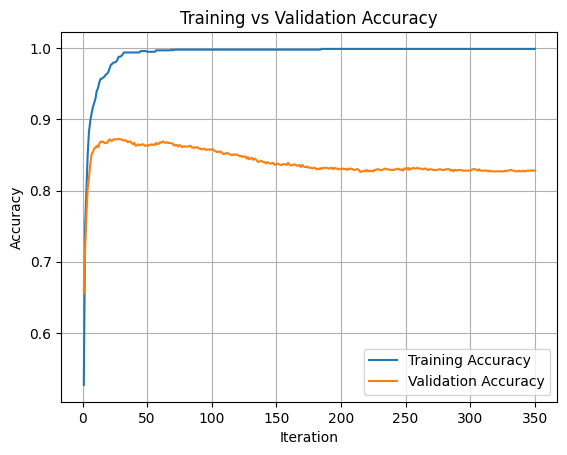

In [8]:
W_0_1, W_1_2, train_hist, val_hist = train(X_train, Y_train, X_val, Y_val, iterations)

# Find the best validation accuracy
best_iteration = np.argmax(val_hist) + 1
best_val_acc = val_hist[best_iteration - 1]
print(f"Validation accuracy peaked at iteration {best_iteration} with accuracy {best_val_acc:.4f}")

# ---- Plot ----
plt.plot(range(1, iterations + 1), train_hist, label="Training Accuracy")
plt.plot(range(1, iterations + 1), val_hist, label="Validation Accuracy")

plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In this section we perform a normal train with a model. The training accuracy increases quickly and plateaus. The validation training, however, falls off quickly and then slowly degrads over time before plateauing at a lower point. This is to demonstrate what overfitting looks like.

## Part 2: Early Stopping

In [12]:
def getHyperParameters(alpha=0.005, hidden_size=40):
    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1
    return alpha, W_0_1, W_1_2


def train_early_stopping(
    X_train, Y_train, X_val, Y_val, iterations=350, patience=10, verbose=False
):
    alpha, W_0_1, W_1_2 = getHyperParameters()

    train_hist = []
    val_hist = []

    # New: variables for early stopping
    best_val = 0.0  # Used to compare with the current validation accuracy
    best_weights = None  # The fallback in case patience runs out
    since_improvement = 0  # How we know when to run out of patience

    for it in range(iterations):
        correct = 0

        for i in range(len(X_train)):
            # ---- Forward ----
            layer_0 = X_train[i : i + 1]
            layer_1 = relu(layer_0.dot(W_0_1))
            layer_2 = layer_1.dot(W_1_2)

            # ---- Score ----
            correct += int(np.argmax(layer_2) == np.argmax(Y_train[i]))

            # ---- Backward ----
            delta_2 = layer_2 - Y_train[i : i + 1]
            delta_1 = delta_2.dot(W_1_2.T) * relu_d(layer_1)

            W_1_2 -= alpha * layer_1.T.dot(delta_2)
            W_0_1 -= alpha * layer_0.T.dot(delta_1)

        train_acc = correct / len(X_train)
        val_acc = evaluate(X_val, Y_val, W_0_1, W_1_2)

        # Check if we're on the right track by comparing
        # the validation accuracy to the best val_acc we
        # have so far
        if val_acc > best_val:
            best_val = val_acc
            if verbose:
                print(f"New best validation accuracy acquired: {best_val:.4f}")
            best_weights = (copy.deepcopy(W_0_1), copy.deepcopy(W_1_2))
            since_improvement = 0
        else:
            since_improvement += 1
            if since_improvement >= patience:
                if verbose:
                    print(f"Stopping at iteration {it}; best val_acc={best_val:.3f}")
                break

        train_hist.append(train_acc)
        val_hist.append(val_acc)

    W_0_1, W_1_2 = best_weights

    return W_0_1, W_1_2, train_hist, val_hist

In [15]:
(X_train, y_train), (X_test, y_test) = load_mnist()
X_val, Y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
X_train, Y_train = X_train[:1000], one_hot(y_train[:1000])

# Set up random seed
np.random.seed(1)

final_w_0_1, final_w_1_2, train_history, val_history = train_early_stopping(
    X_train, Y_train, X_val, Y_val, iterations=350, patience=10, verbose=False
)

print(f"Training history: {train_history}")
print(f"Validation accuracy history: {val_history}")

Training history: [0.527, 0.749, 0.802, 0.851, 0.883, 0.898, 0.908, 0.917, 0.923, 0.929, 0.94, 0.944, 0.952, 0.957, 0.957, 0.959, 0.96, 0.963, 0.964, 0.967, 0.972, 0.977, 0.978, 0.98, 0.98, 0.981, 0.984, 0.988, 0.988, 0.989, 0.991, 0.994, 0.994, 0.994, 0.994, 0.994, 0.994]
Validation accuracy history: [0.656, 0.718, 0.764, 0.804, 0.818, 0.837, 0.851, 0.854, 0.859, 0.86, 0.863, 0.861, 0.866, 0.869, 0.868, 0.869, 0.867, 0.867, 0.867, 0.87, 0.872, 0.87, 0.87, 0.872, 0.872, 0.872, 0.872, 0.873, 0.872, 0.872, 0.871, 0.87, 0.871, 0.87, 0.868, 0.869, 0.869]


This section is early stopping. The training loop cuts off early if the performance continues to degrade over time instead of getting worse.

## Part 3: Dropout

In [16]:
def train_dropout(X_train, Y_train, X_val, Y_val, iterations=350, dropout = True):
    np.random.seed(1)
    alpha = 0.005
    hidden_size = 40

    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    train_hist = []
    val_hist = []

    for it in range(iterations):
        correct = 0

        for i in range(len(X_train)):
            # ---- Forward ----
            layer_0 = X_train[i:i+1]
            layer_1 = relu(layer_0.dot(W_0_1))

            # default to no mask...
            mask = np.ones(layer_1.shape)
            # but if we are using a mask, generate and apply it here
            if dropout == True:
                mask = np.random.randint(2, size=layer_1.shape) # ~50% ones, ~50% zeros
                layer_1 *= mask * 2 # zero (on average) half, double the rest


            layer_2 = layer_1.dot(W_1_2)

            # ---- Score ----
            correct += int(np.argmax(layer_2) == np.argmax(Y_train[i]))

            # ---- Backward ----
            delta_2 = layer_2 - Y_train[i:i+1]
            # make sure not to modify any weights by masked values!
            # If they didn't contribute to the final run, don't modify them
            # as if they did!
            delta_1 = delta_2.dot(W_1_2.T) * relu_d(layer_1) * mask # mask is all 1s if dropout is false, else it's the dropout list

            W_1_2 -= alpha * layer_1.T.dot(delta_2)
            W_0_1 -= alpha * layer_0.T.dot(delta_1)

        train_acc = correct / len(X_train)
        val_acc = evaluate(X_val, Y_val, W_0_1, W_1_2)

        train_hist.append(train_acc)
        val_hist.append(val_acc)

#        print(f"Iteration {it+1}/{iterations} - Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

    return W_0_1, W_1_2, train_hist, val_hist

Without Dropout:
________________
Final training round's accuracy on the training set was:
0.999
Final weights' accuracy on the training set was:
0.999
Best validation accuracy, in pass 28, was:
0.873
Final validation accuracy was:
0.828
With Dropout:
_____________
Final training round's accuracy on the training set was:
0.883
Final weights' accuracy on the training set was:
0.995
Best validation accuracy, in pass 54, was:
0.869
Final validation accuracy was:
0.853


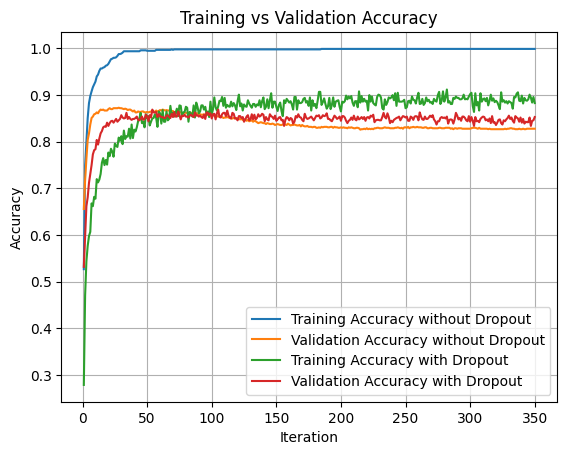

In [22]:
(X_train, y_train), (X_test, y_test) = load_mnist()
X_val, Y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
X_train, Y_train = X_train[:1000], one_hot(y_train[:1000])

np.random.seed(1) # seed FIRST, then initialise
alpha, hidden_size, iterations, batch_size = 0.1, 40, 350, 100
W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1 # [-0.1, 0.1)
W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

W_0_1_contr, W_1_2_contr, train_hist_control, val_hist_control = train_dropout(X_train, Y_train, X_val, Y_val, iterations, False)
W_0_1_drop, W_1_2_drop, train_hist_dropout, val_hist_dropout = train_dropout(X_train, Y_train, X_val, Y_val, iterations, True)
best_pass_c = np.argmax(val_hist_control) + 1
best_val_acc_c = val_hist_control[best_pass_c-1]
best_pass_d = np.argmax(val_hist_dropout) + 1
best_val_acc_d = val_hist_dropout[best_pass_d-1]

print("Without Dropout:")
print("________________")
print("Final training round's accuracy on the training set was:")
print(train_hist_control[-1])
print("Final weights' accuracy on the training set was:")
print(evaluate(X_train, Y_train, W_0_1_contr, W_1_2_contr))
print(f"Best validation accuracy, in pass {best_pass_c}, was:")
print(best_val_acc_c)
print("Final validation accuracy was:")
print(val_hist_control[-1])

print("With Dropout:")
print("_____________")
print("Final training round's accuracy on the training set was:")
print(train_hist_dropout[-1])
print("Final weights' accuracy on the training set was:")
print(evaluate(X_train, Y_train, W_0_1_drop, W_1_2_drop))
print(f"Best validation accuracy, in pass {best_pass_d}, was:")
print(best_val_acc_d)
print("Final validation accuracy was:")
print(val_hist_dropout[-1])

plt.plot(range(1, iterations + 1), train_hist_control, label="Training Accuracy without Dropout")
plt.plot(range(1, iterations + 1), val_hist_control, label="Validation Accuracy without Dropout")
plt.plot(range(1, iterations + 1), train_hist_dropout, label="Training Accuracy with Dropout")
plt.plot(range(1, iterations + 1), val_hist_dropout, label="Validation Accuracy with Dropout")

plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In this section we implement dropout. This comparison shows how constraining the model helps it generalize better to the validation data. We experience less divergence from training/validation with this.

## Part 4: Batching

In [23]:
def train_batched(X_train, Y_train, X_val, Y_val, alpha = 0.005, iterations=350, batch_size=100, dropout = True):
    start_time = time.perf_counter()
    np.random.seed(1)
    alpha = alpha
    hidden_size = 40

    W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    train_hist = []
    val_hist = []

    for it in range(iterations):
        correct = 0

        for i in range(len(X_train) // batch_size):
            start, end = i * batch_size, (i+1) * batch_size
            # ---- Forward ----
            layer_0 = X_train[start:end]
            layer_1 = relu(layer_0.dot(W_0_1))

            # default to no mask...
            mask = np.ones(layer_1.shape)
            # but if we are using a mask, generate and apply it here
            if dropout == True:
                mask = np.random.randint(2, size=layer_1.shape) # ~50% ones, ~50% zeros
                layer_1 *= mask * 2 # zero (on average) half, double the rest


            layer_2 = layer_1.dot(W_1_2)

            # ---- Score ----
            correct += np.sum(np.argmax(layer_2, axis=1) == np.argmax(Y_train[start:end], axis=1))

            # ---- Backward ----
            delta_2 = (layer_2 - Y_train[start:end]) / batch_size
            # make sure not to modify any weights by masked values!
            # If they didn't contribute to the final run, don't modify them
            # as if they did!
            delta_1 = delta_2.dot(W_1_2.T) * relu_d(layer_1) * mask # mask is all 1s if dropout is false, else it's the dropout list

            W_1_2 -= alpha * layer_1.T.dot(delta_2)
            W_0_1 -= alpha * layer_0.T.dot(delta_1)

        train_acc = correct / len(X_train)
        val_acc = evaluate(X_val, Y_val, W_0_1, W_1_2)

        train_hist.append(train_acc)
        val_hist.append(val_acc)

        # print(f"Iteration {it+1}/{iterations} - Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

    end_time = time.perf_counter()
    return W_0_1, W_1_2, train_hist, val_hist, end_time - start_time

In [25]:
(X_train, y_train), (X_test, y_test) = load_mnist()
X_val, Y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
X_train, Y_train = X_train[:1000], one_hot(y_train[:1000])

np.random.seed(1) # seed FIRST, then initialise
alpha, hidden_size, iterations, batch_size = 0.1, 40, 350, 100
W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1 # [-0.1, 0.1)
W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

W_0_1_batch, W_1_2_batch, train_hist_batch, val_hist_batch, time_taken_batch = train_batched(X_train, Y_train, X_val, Y_val, alpha, iterations, batch_size, True)

best_pass_b = np.argmax(val_hist_batch) + 1
best_val_acc_b = val_hist_batch[best_pass_b-1]

print("With Batching:")
print("________________")
print("Final training round's accuracy on the training set was:")
print(train_hist_batch[-1])
print("Final weights' accuracy on the training set was:")
print(evaluate(X_train, Y_train, W_0_1_batch, W_1_2_batch))
print(f"Best validation accuracy, in pass {best_pass_b}, was:")
print(best_val_acc_b)
print("Final validation accuracy was:")
print(val_hist_batch[-1])

W_0_1 = 0.2 * np.random.random((784, hidden_size)) - 0.1 # [-0.1, 0.1)
W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

start_time = time.perf_counter()
W_0_1_drop, W_1_2_drop, train_hist_dropout, val_hist_dropout = train_dropout(X_train, Y_train, X_val, Y_val, iterations, True)
end_time = time.perf_counter()
time_taken_drop = end_time - start_time

best_pass_d = np.argmax(val_hist_dropout) + 1
best_val_acc_d = val_hist_dropout[best_pass_d-1]
print("Without Batching:")
print("________________")
print("Final training round's accuracy on the training set was:")
print(train_hist_dropout[-1])
print("Final weights' accuracy on the training set was:")
print(evaluate(X_train, Y_train, W_0_1_drop, W_1_2_drop))
print(f"Best validation accuracy, in pass {best_pass_d}, was:")
print(best_val_acc_d)
print("Final validation accuracy was:")
print(val_hist_dropout[-1])

print("\nTime Taken Difference\n")
print(f"Batching: {time_taken_batch}")
print(f"Without Batching: {time_taken_drop}")

With Batching:
________________
Final training round's accuracy on the training set was:
0.857
Final weights' accuracy on the training set was:
0.986
Best validation accuracy, in pass 267, was:
0.864
Final validation accuracy was:
0.842
Without Batching:
________________
Final training round's accuracy on the training set was:
0.883
Final weights' accuracy on the training set was:
0.995
Best validation accuracy, in pass 54, was:
0.869
Final validation accuracy was:
0.853

Time Taken Difference

Batching: 17.28398834399968
Without Batching: 62.38672665000013


With batching, we can gain a level of efficiency as well as smoothing out the weight training gradient by using batching. Getting an average for updating weights instead of bouncing around with each update in a more jagged way.